# Trial 5 — Multi-Channel Frames + Trajectory Loss

**What changed from Trial 4:**

**Inputs (the big one):** Each pixel now carries 5 channels per timestep, not 1:
1. Raw correlation
2. 1-step delta — short-term rate of change
3. 5-step delta — medium-term rate of change
4. 4-step rolling mean — smoothed context
5. 4-step rolling std — relationship volatility

Channels 2 vs 3 give multi-scale temporal info; channels 4 and 5 capture local regime. The model sees the full *state* of each pair-relationship at every timestep, not just its current correlation value.

**Loss:** Added a trajectory-magnitude term — predicted change magnitude should match actual change magnitude. Directional loss now masked to ignore noise-level moves (|true_delta| > 0.005).

**Architecture:** Dropped 3D CNN (consistently weakest in T2/T3/T4). Only CNN+LSTM and ConvLSTM, both modified to accept multi-channel input.

**Scheduler:** `T_0=20` instead of 10 (Trial 4 all stopped at ep22 because cycle 1 was too short). PATIENCE=15.

**Ensemble:** Inverse-MSE weighted instead of simple average.

**Output prefix:** `trial5_*`. No files need deleting.

In [1]:
# Cell 1 – Imports & Configuration
import os, time, copy, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# ── Paths ─────────────────────────────────────────────────────────────────────
_cwd        = os.getcwd()
PROJECT_DIR = os.path.abspath(os.path.join(_cwd, '..')) \
              if os.path.basename(_cwd) == 'notebooks' else _cwd
DATA_DIR    = os.path.join(PROJECT_DIR, 'data', 'processed')
MODELS_DIR  = os.path.join(PROJECT_DIR, 'models')
PREDS_DIR   = os.path.join(PROJECT_DIR, 'outputs', 'predictions')
PLOTS_DIR   = os.path.join(PROJECT_DIR, 'outputs', 'plots')

# ── Hyperparameters ───────────────────────────────────────────────────────────
N_STOCKS    = 95
LOOKBACK    = 20
HORIZON     = 5
TRAIN_RATIO = 0.70

# Multi-channel input
N_CHANNELS    = 5      # raw, d1, d5, rolling_mean, rolling_std
DELTA_SHORT   = 1
DELTA_LONG    = 5
ROLLING_WIN   = 4

BATCH_SIZE    = 16
LR            = 1e-3
MAX_EPOCHS    = 60
WEIGHT_DECAY  = 1e-4

# Cosine annealing — LONGER first cycle (T4 stopped at ep22 with T_0=10)
T_0     = 20
T_MULT  = 2
ETA_MIN = 1e-6
PATIENCE = 15

# Combined loss weights
# alpha = MSE | beta = 1−Pearson | gamma = directional (mag-masked) | delta = trajectory mag
ALPHA = 0.35
BETA  = 0.25
GAMMA = 0.30
DELTA = 0.10
DIR_MAG_THRESH = 0.005   # ignore directional errors on tiny noise moves

device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PIN_MEM = device.type == 'cuda'

print(f'Device      : {device}')
print(f'PyTorch     : {torch.__version__}')
print(f'Channels/px : {N_CHANNELS}')
print(f'Scheduler   : CosineAnnealingWarmRestarts  T_0={T_0}  T_mult={T_MULT}')
print(f'Patience    : {PATIENCE} epochs')
print(f'Loss        : a={ALPHA} MSE | b={BETA} Pearson | g={GAMMA} Dir(mask>{DIR_MAG_THRESH}) | d={DELTA} Traj')


Device      : cuda
PyTorch     : 2.6.0+cu124
Channels/px : 5
Scheduler   : CosineAnnealingWarmRestarts  T_0=20  T_mult=2
Patience    : 15 epochs
Loss        : a=0.35 MSE | b=0.25 Pearson | g=0.3 Dir(mask>0.005) | d=0.1 Traj


In [2]:
# Cell 2 – Load Processed Data
corr_video  = np.load(os.path.join(DATA_DIR, 'corr_video.npy'))
fiedler_ord = np.load(os.path.join(DATA_DIR, 'fiedler_order.npy'))
snap_ts     = np.load(os.path.join(DATA_DIR, 'snap_timesteps.npy'), allow_pickle=True)

with open(os.path.join(DATA_DIR, 'pair_meta.pkl'), 'rb') as f:
    pair_meta = pickle.load(f)
with open(os.path.join(DATA_DIR, 'video_meta.pkl'), 'rb') as f:
    video_meta = pickle.load(f)

tickers = pair_meta['tickers']
N_SNAPS = corr_video.shape[0]

print(f'corr_video  : {corr_video.shape}  dtype={corr_video.dtype}')
print(f'N stocks    : {len(tickers)}')
print(f'N snapshots : {N_SNAPS}')
print(f'Snap range  : {snap_ts[0]} -> {snap_ts[-1]}')


corr_video  : (1157, 95, 95)  dtype=float32
N stocks    : 95
N snapshots : 1157
Snap range  : 375 -> 87075


In [3]:
# Cell 3 – Build Multi-Channel Video
# Each frame becomes (C, H, W) instead of (H, W). The C channels carry
# multiple "views" of every pair-relationship: raw, deltas, rolling stats.
# This gives the model a richer per-pixel state to learn from.

def build_multichannel_video(corr_video, delta_short=1, delta_long=5, win=4):
    T, H, W = corr_video.shape
    C = 5
    out = np.zeros((T, C, H, W), dtype=np.float32)
    out[:, 0] = corr_video                                              # raw

    # Causal deltas (left-padded with zeros)
    out[delta_short:, 1] = corr_video[delta_short:] - corr_video[:-delta_short]
    out[delta_long:,  2] = corr_video[delta_long:]  - corr_video[:-delta_long]

    # Causal rolling mean and std via cumulative sums
    cum  = np.cumsum(corr_video,    axis=0)
    cum2 = np.cumsum(corr_video**2, axis=0)
    for t in range(T):
        lo = max(0, t - win + 1)
        n  = t - lo + 1
        s   = cum[t]  - (cum[lo-1]  if lo > 0 else 0.0)
        s2  = cum2[t] - (cum2[lo-1] if lo > 0 else 0.0)
        mean = s / n
        var  = np.maximum(0.0, s2 / n - mean**2)
        out[t, 3] = mean
        out[t, 4] = np.sqrt(var)
    return out

multichannel_video = build_multichannel_video(
    corr_video, DELTA_SHORT, DELTA_LONG, ROLLING_WIN
)

print(f'multichannel_video : {multichannel_video.shape}  '
      f'~{multichannel_video.nbytes / 1e6:.0f} MB')
print('Channel summary:')
for c, name in enumerate(['raw', 'd_short', 'd_long', 'roll_mean', 'roll_std']):
    a = multichannel_video[:, c]
    print(f'  [{c}] {name:>10}  min={a.min():+.4f}  max={a.max():+.4f}  mean={a.mean():+.4f}')


multichannel_video : (1157, 5, 95, 95)  ~209 MB
Channel summary:
  [0]        raw  min=-0.9891  max=+1.0000  mean=+0.2237
  [1]    d_short  min=-1.8732  max=+1.8399  mean=+0.0003
  [2]     d_long  min=-1.8773  max=+1.8363  mean=+0.0012
  [3]  roll_mean  min=-0.8772  max=+1.0000  mean=+0.2233
  [4]   roll_std  min=+0.0000  max=+0.8419  mean=+0.1926


In [4]:
# Cell 4 – Frame MSE, Stratified Split, Dataset & DataLoaders

n_valid   = N_SNAPS - HORIZON
frame_mse = np.array([
    float(np.mean((corr_video[t] - corr_video[t + HORIZON]) ** 2))
    for t in range(n_valid)
], dtype=np.float32)

volatility_threshold = float(np.median(frame_mse))
print(f'Volatility threshold: {volatility_threshold:.6f}')

valid_snaps = np.array([s for s in range(n_valid) if s >= LOOKBACK])
snap_v      = frame_mse[valid_snaps]

volatile_snaps = valid_snaps[snap_v >= volatility_threshold]
stable_snaps   = valid_snaps[snap_v <  volatility_threshold]

np.random.seed(42)
vol_train = np.random.choice(volatile_snaps, int(len(volatile_snaps) * TRAIN_RATIO), replace=False)
vol_val   = np.setdiff1d(volatile_snaps, vol_train)
sta_train = np.random.choice(stable_snaps,  int(len(stable_snaps)  * TRAIN_RATIO), replace=False)
sta_val   = np.setdiff1d(stable_snaps, sta_train)

train_snaps = np.sort(np.concatenate([vol_train, sta_train]))
val_snaps   = np.sort(np.concatenate([vol_val,   sta_val]))

print(f'Train: {len(train_snaps)} ({len(vol_train)} vol, {len(sta_train)} sta)')
print(f'Val  : {len(val_snaps)}   ({len(vol_val)} vol, {len(sta_val)} sta)')

# ── Baselines ──────────────────────────────────────────────────────────────────
persistence_mse  = float(np.mean([
    np.mean((corr_video[s] - corr_video[s + HORIZON]) ** 2) for s in val_snaps
]))
mean_train_frame = corr_video[train_snaps].mean(axis=0)
mean_frame_mse   = float(np.mean([
    np.mean((mean_train_frame - corr_video[s + HORIZON]) ** 2) for s in val_snaps
]))
val_currents = corr_video[val_snaps - 1].astype(np.float32)

print(f'\nPersistence MSE : {persistence_mse:.6f}')
print(f'Mean-frame MSE  : {mean_frame_mse:.6f}')

# ── Dataset (multi-channel) ────────────────────────────────────────────────────
class CorrVideoDataset(Dataset):
    def __init__(self, snap_indices):
        self.snaps = snap_indices
    def __len__(self):
        return len(self.snaps)
    def __getitem__(self, idx):
        s       = self.snaps[idx]
        frames  = multichannel_video[s - LOOKBACK : s].astype(np.float32)  # (L, C, H, W)
        future  = corr_video[s + HORIZON].astype(np.float32)               # (H, W)
        current = corr_video[s - 1].astype(np.float32)                     # (H, W)
        weight  = float(frame_mse[s])
        return (
            torch.from_numpy(frames),
            torch.from_numpy(future),
            torch.from_numpy(current),
            torch.tensor(weight, dtype=torch.float32),
        )

train_ds = CorrVideoDataset(train_snaps)
val_ds   = CorrVideoDataset(val_snaps)
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=PIN_MEM)
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=PIN_MEM)

_f, _y, _c, _w = train_ds[0]
print(f'\nDataset ready  train={len(train_ds)}  val={len(val_ds)}')
print(f'Sample shapes  frames={tuple(_f.shape)}  future={tuple(_y.shape)}  current={tuple(_c.shape)}')


Volatility threshold: 0.121262
Train: 792 (389 vol, 403 sta)
Val  : 340   (167 vol, 173 sta)

Persistence MSE : 0.128137
Mean-frame MSE  : 0.071299

Dataset ready  train=792  val=340
Sample shapes  frames=(20, 5, 95, 95)  future=(95, 95)  current=(95, 95)


In [5]:
# Cell 5 – Combined Loss Function (4 terms)

def combined_loss(pred, target, current, weights,
                  alpha=ALPHA, beta=BETA, gamma=GAMMA, delta=DELTA,
                  dir_thresh=DIR_MAG_THRESH):
    """
    pred, target, current : (B, N, N)
    weights               : (B,)
    """
    # 1. Volatility-weighted MSE
    per_sample = ((pred - target) ** 2).mean(dim=(1, 2))
    w          = weights / weights.sum() * len(weights)
    mse_loss   = (w * per_sample).mean()

    # 2. Pearson correlation loss
    pred_flat = pred.flatten(1)
    tgt_flat  = target.flatten(1)
    pred_c    = pred_flat - pred_flat.mean(dim=1, keepdim=True)
    tgt_c     = tgt_flat  - tgt_flat.mean(dim=1, keepdim=True)
    pearson   = (pred_c * tgt_c).sum(dim=1) / (
                 pred_c.norm(dim=1) * tgt_c.norm(dim=1) + 1e-8)
    pearson_loss = (1.0 - pearson).mean()

    # 3. Magnitude-masked directional loss
    pred_delta = pred   - current
    true_delta = target - current
    mag_mask   = (true_delta.abs() > dir_thresh).float()
    dir_raw    = F.relu(-(pred_delta * true_delta))
    denom      = mag_mask.sum().clamp(min=1.0)
    dir_loss   = (dir_raw * mag_mask).sum() / denom

    # 4. NEW: Trajectory magnitude loss
    # The size of predicted change should match the size of actual change
    traj_loss = (pred_delta.abs() - true_delta.abs()).pow(2).mean()

    return alpha * mse_loss + beta * pearson_loss + gamma * dir_loss + delta * traj_loss


# Sanity check
with torch.no_grad():
    _p = torch.randn(4, N_STOCKS, N_STOCKS)
    _t = torch.randn(4, N_STOCKS, N_STOCKS)
    _c = torch.randn(4, N_STOCKS, N_STOCKS)
    _w = torch.ones(4)
    _l = combined_loss(_p, _t, _c, _w)
print(f'Combined loss sanity check: {_l.item():.4f}  (should be > 0)')


Combined loss sanity check: 1.1194  (should be > 0)


In [6]:
# Cell 6 – Model Architectures (CNN+LSTM and ConvLSTM, multi-channel input)
# 3D CNN removed — consistently weakest in T2/T3/T4 and 13× slower per epoch.

# ── Model 1: CNN + LSTM ────────────────────────────────────────────────────────
class FrameCNN(nn.Module):
    def __init__(self, in_channels=N_CHANNELS, out_dim=256):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 16, 5, padding=2)
        self.conv2 = nn.Conv2d(16, 32, 5, padding=2)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn1   = nn.BatchNorm2d(16)
        self.bn2   = nn.BatchNorm2d(32)
        self.bn3   = nn.BatchNorm2d(64)
        self.pool  = nn.MaxPool2d(2, 2)
        self.drop  = nn.Dropout2d(0.2)
        self.apool = nn.AdaptiveAvgPool2d((6, 6))
        self.fc    = nn.Linear(64 * 6 * 6, out_dim)
        self.norm  = nn.LayerNorm(out_dim)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.drop(self.pool(F.relu(self.bn2(self.conv2(x)))))
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.apool(x).flatten(1)
        return self.norm(F.relu(self.fc(x)))


class CorrVideoReg(nn.Module):
    def __init__(self, cnn_dim=256, lstm_hidden=256, lstm_layers=2,
                 n_stocks=N_STOCKS, n_channels=N_CHANNELS, dropout=0.3):
        super().__init__()
        self.n       = n_stocks
        self.cnn     = FrameCNN(in_channels=n_channels, out_dim=cnn_dim)
        self.lstm    = nn.LSTM(cnn_dim, lstm_hidden, lstm_layers,
                               batch_first=True,
                               dropout=dropout if lstm_layers > 1 else 0.0)
        self.norm    = nn.LayerNorm(lstm_hidden)
        self.dropout = nn.Dropout(dropout)
        self.decoder = nn.Sequential(
            nn.Linear(lstm_hidden, 512),  nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(512, 1024),         nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(1024, n_stocks * n_stocks), nn.Tanh()
        )

    def forward(self, frames):
        # frames: (B, L, C, H, W)
        B, L, C, H, W = frames.shape
        cnn_out = self.cnn(frames.reshape(B * L, C, H, W))
        cnn_seq = cnn_out.reshape(B, L, -1)
        out, _  = self.lstm(cnn_seq)
        h       = self.dropout(self.norm(out[:, -1, :]))
        return self.decoder(h).reshape(B, self.n, self.n)


# ── Model 2: ConvLSTM ──────────────────────────────────────────────────────────
class ConvLSTMCell(nn.Module):
    def __init__(self, in_ch, hid_ch, k=3):
        super().__init__()
        self.hid_ch = hid_ch
        self.conv   = nn.Conv2d(in_ch + hid_ch, 4 * hid_ch, k, padding=k // 2)

    def forward(self, x, h, c):
        i, f, g, o = self.conv(torch.cat([x, h], dim=1)).chunk(4, dim=1)
        c_next = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h_next = torch.sigmoid(o) * torch.tanh(c_next)
        return h_next, c_next

    def init_hidden(self, B, sp, device):
        z = torch.zeros(B, self.hid_ch, sp, sp, device=device)
        return z, z.clone()


class ConvLSTMReg(nn.Module):
    def __init__(self, n_stocks=N_STOCKS, n_channels=N_CHANNELS,
                 sp=24, hid_ch=32, dropout=0.3):
        super().__init__()
        self.n      = n_stocks
        self.sp     = sp
        self.hid_ch = hid_ch
        self.down   = nn.Sequential(
            nn.Conv2d(n_channels, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1),         nn.BatchNorm2d(32), nn.ReLU(),
            nn.AdaptiveAvgPool2d((sp, sp)),
            nn.Conv2d(32, hid_ch, 1),
        )
        self.cell1  = ConvLSTMCell(hid_ch, hid_ch)
        self.cell2  = ConvLSTMCell(hid_ch, hid_ch)
        self.lnorm  = nn.LayerNorm([hid_ch, sp, sp])
        self.drop2d = nn.Dropout2d(dropout)
        flat        = hid_ch * sp * sp
        self.decoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat, 1024), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(1024, 2048), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(2048, n_stocks * n_stocks), nn.Tanh()
        )

    def forward(self, frames):
        # frames: (B, L, C, H, W)
        B, L, C, H, W = frames.shape
        enc = self.down(frames.reshape(B * L, C, H, W))
        enc = enc.reshape(B, L, self.hid_ch, self.sp, self.sp)
        h1, c1 = self.cell1.init_hidden(B, self.sp, frames.device)
        h2, c2 = self.cell2.init_hidden(B, self.sp, frames.device)
        for t in range(L):
            h1, c1 = self.cell1(enc[:, t], h1, c1)
            h1     = self.drop2d(h1)
            h2, c2 = self.cell2(h1, h2, c2)
        h2 = self.lnorm(h2)
        return self.decoder(h2).reshape(B, self.n, self.n)


def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

_m1 = CorrVideoReg().to(device)
_m2 = ConvLSTMReg().to(device)
print(f'CNN+LSTM   params: {n_params(_m1):>10,}')
print(f'ConvLSTM   params: {n_params(_m2):>10,}')
del _m1, _m2


CNN+LSTM   params: 11,584,865
ConvLSTM   params: 39,657,921


In [7]:
# Cell 7 – Training Utilities

def run_epoch(model, loader, optimizer, is_train, desc=''):
    model.train() if is_train else model.eval()
    total_loss = total_n = 0
    all_preds, all_futs = [], []

    ctx  = torch.enable_grad() if is_train else torch.no_grad()
    pbar = tqdm(loader, desc=desc, ncols=100, leave=False)

    with ctx:
        for frames, future, current, w in pbar:
            frames  = frames.to(device)
            future  = future.to(device)
            current = current.to(device)
            w       = w.to(device)

            pred = model(frames)
            loss = combined_loss(pred, future, current, w)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            total_loss += loss.item() * frames.size(0)
            total_n    += frames.size(0)
            all_preds.append(pred.detach().cpu().numpy())
            all_futs.append(future.cpu().numpy())
            pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    return total_loss / total_n, np.concatenate(all_preds), np.concatenate(all_futs)


def compute_metrics(preds, futures, currents=None):
    mse  = float(np.mean((preds - futures) ** 2))
    pf   = preds.reshape(-1)
    ff   = futures.reshape(-1)
    r, _ = pearsonr(pf[:500_000], ff[:500_000])
    vs_persist = (persistence_mse - mse) / persistence_mse * 100
    vs_mean    = (mean_frame_mse  - mse) / mean_frame_mse  * 100
    if currents is not None:
        pd_ = preds   - currents
        td_ = futures - currents
        dir_acc = float(np.mean(np.sign(pd_) == np.sign(td_)))
    else:
        dir_acc = None
    return dict(mse=mse, pearson_r=r, dir_acc=dir_acc,
                vs_persist=vs_persist, vs_mean=vs_mean)


def train_model(model, name, save_path, t_dl, v_dl):
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
                    optimizer, T_0=T_0, T_mult=T_MULT, eta_min=ETA_MIN)

    best_val_mse = float('inf')
    patience_ctr = 0
    history      = []
    best_preds   = None

    print(f'\n{"="*65}')
    print(f'Training: {name}')
    print(f'Scheduler cycles: T_0={T_0} -> {T_0*T_MULT} -> {T_0*T_MULT*T_MULT} epochs')
    print(f'{"="*65}')

    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time()

        tr_loss, _,        _       = run_epoch(model, t_dl, optimizer, True,
                                               desc=f'Ep {epoch:>2} Train')
        va_loss, va_preds, va_futs = run_epoch(model, v_dl, optimizer, False,
                                               desc=f'Ep {epoch:>2} Val  ')

        scheduler.step()
        m      = compute_metrics(va_preds, va_futs, val_currents)
        lr_now = optimizer.param_groups[0]['lr']
        improved = ' *' if m['mse'] < best_val_mse else ''

        history.append(dict(epoch=epoch, tr_loss=tr_loss, va_mse=m['mse'],
                            pearson_r=m['pearson_r'], dir_acc=m['dir_acc'], lr=lr_now))

        print(f"Ep {epoch:>2}/{MAX_EPOCHS} | "
              f"tr={tr_loss:.5f} | va={m['mse']:.5f} | "
              f"r={m['pearson_r']:.4f} | dir={m['dir_acc']:.3f} | "
              f"vs_pers={m['vs_persist']:+.1f}% | vs_mean={m['vs_mean']:+.1f}% | "
              f"lr={lr_now:.2e} | {time.time()-t0:.0f}s{improved}")

        if m['mse'] < best_val_mse:
            best_val_mse = m['mse']
            patience_ctr = 0
            best_preds   = va_preds.copy()
            torch.save(model.state_dict(), save_path)
        else:
            patience_ctr += 1
            if patience_ctr >= PATIENCE:
                print(f'\nEarly stopping at epoch {epoch}  best_val_mse={best_val_mse:.6f}')
                break

    print(f'\nBest val MSE: {best_val_mse:.6f}')
    model.load_state_dict(torch.load(save_path, map_location=device, weights_only=True))
    return history, best_preds


print('Training utilities ready.')


Training utilities ready.


In [8]:
# Cell 8 – Train CNN+LSTM

model_cnn_lstm = CorrVideoReg(n_stocks=N_STOCKS, n_channels=N_CHANNELS).to(device)
save_cnn_lstm  = os.path.join(MODELS_DIR, 'trial5_cnn_lstm_best.pt')

hist_cnn_lstm, preds_cnn_lstm = train_model(
    model_cnn_lstm, 'CNN+LSTM', save_cnn_lstm, train_dl, val_dl
)

np.save(os.path.join(PREDS_DIR, 'trial5_cnn_lstm_val_preds.npy'), preds_cnn_lstm)
with open(os.path.join(MODELS_DIR, 'trial5_cnn_lstm_history.pkl'), 'wb') as f:
    pickle.dump(hist_cnn_lstm, f)
print('CNN+LSTM done.')



Training: CNN+LSTM
Scheduler cycles: T_0=20 -> 40 -> 80 epochs


Ep  1/60 | tr=0.20838 | va=0.07661 | r=0.2856 | dir=0.714 | vs_pers=+40.2% | vs_mean=-7.5% | lr=9.94e-04 | 9s *


Ep  2/60 | tr=0.18854 | va=0.08153 | r=0.2962 | dir=0.701 | vs_pers=+36.4% | vs_mean=-14.4% | lr=9.76e-04 | 8s


Ep  3/60 | tr=0.18572 | va=0.07545 | r=0.3028 | dir=0.715 | vs_pers=+41.1% | vs_mean=-5.8% | lr=9.46e-04 | 8s *


Ep  4/60 | tr=0.18446 | va=0.07516 | r=0.2920 | dir=0.713 | vs_pers=+41.3% | vs_mean=-5.4% | lr=9.05e-04 | 8s *


...

Ep 29/60 | tr=0.17939 | va=0.07146 | r=0.3312 | dir=0.723 | vs_pers=+44.2% | vs_mean=-0.2% | lr=8.80e-04 | 8s


Ep 30/60 | tr=0.17805 | va=0.07336 | r=0.3201 | dir=0.720 | vs_pers=+42.7% | vs_mean=-2.9% | lr=8.54e-04 | 7s


Ep 31/60 | tr=0.17910 | va=0.07115 | r=0.3292 | dir=0.724 | vs_pers=+44.5% | vs_mean=+0.2% | lr=8.25e-04 | 8s


Ep 32/60 | tr=0.17821 | va=0.07271 | r=0.3007 | dir=0.721 | vs_pers=+43.3% | vs_mean=-2.0% | lr=7.94e-04 | 8s


Ep 33/60 | tr=0.17831 | va=0.07018 | r=0.3612 | dir=0.726 | vs_pers=+45.2% | vs_mean=+1.6% | lr=7.61e-04 | 8s

Early stopping at epoch 33  best_val_mse=0.069239

Best val MSE: 0.069239
CNN+LSTM done.


In [9]:
# Cell 9 – Train ConvLSTM

model_convlstm = ConvLSTMReg(n_stocks=N_STOCKS, n_channels=N_CHANNELS).to(device)
save_convlstm  = os.path.join(MODELS_DIR, 'trial5_convlstm_best.pt')

hist_convlstm, preds_convlstm = train_model(
    model_convlstm, 'ConvLSTM', save_convlstm, train_dl, val_dl
)

np.save(os.path.join(PREDS_DIR, 'trial5_convlstm_val_preds.npy'), preds_convlstm)
with open(os.path.join(MODELS_DIR, 'trial5_convlstm_history.pkl'), 'wb') as f:
    pickle.dump(hist_convlstm, f)
print('ConvLSTM done.')



Training: ConvLSTM
Scheduler cycles: T_0=20 -> 40 -> 80 epochs


Ep  1/60 | tr=0.22014 | va=0.07473 | r=0.2674 | dir=0.718 | vs_pers=+41.7% | vs_mean=-4.8% | lr=9.94e-04 | 13s *


Ep  2/60 | tr=0.19014 | va=0.07225 | r=0.2926 | dir=0.722 | vs_pers=+43.6% | vs_mean=-1.3% | lr=9.76e-04 | 13s *


Ep  3/60 | tr=0.19161 | va=0.08536 | r=0.3044 | dir=0.694 | vs_pers=+33.4% | vs_mean=-19.7% | lr=9.46e-04 | 13s


Ep  4/60 | tr=0.18780 | va=0.07740 | r=0.3276 | dir=0.710 | vs_pers=+39.6% | vs_mean=-8.6% | lr=9.05e-04 | 13s


...

Ep 29/60 | tr=0.17789 | va=0.07189 | r=0.3310 | dir=0.722 | vs_pers=+43.9% | vs_mean=-0.8% | lr=8.80e-04 | 13s


Ep 30/60 | tr=0.17572 | va=0.07069 | r=0.3290 | dir=0.726 | vs_pers=+44.8% | vs_mean=+0.9% | lr=8.54e-04 | 13s


Ep 31/60 | tr=0.17581 | va=0.07037 | r=0.3500 | dir=0.726 | vs_pers=+45.1% | vs_mean=+1.3% | lr=8.25e-04 | 13s


Ep 32/60 | tr=0.17526 | va=0.07069 | r=0.3425 | dir=0.725 | vs_pers=+44.8% | vs_mean=+0.9% | lr=7.94e-04 | 13s


Ep 33/60 | tr=0.17572 | va=0.07059 | r=0.3413 | dir=0.726 | vs_pers=+44.9% | vs_mean=+1.0% | lr=7.61e-04 | 13s

Early stopping at epoch 33  best_val_mse=0.068600

Best val MSE: 0.068600
ConvLSTM done.


In [10]:
# Cell 10 – Weighted Ensemble (inverse-MSE)

p1 = np.load(os.path.join(PREDS_DIR, 'trial5_cnn_lstm_val_preds.npy'))
p2 = np.load(os.path.join(PREDS_DIR, 'trial5_convlstm_val_preds.npy'))

val_futures = corr_video[val_snaps + HORIZON].astype(np.float32)
m1 = compute_metrics(p1, val_futures, val_currents)
m2 = compute_metrics(p2, val_futures, val_currents)

w1 = 1.0 / m1['mse']
w2 = 1.0 / m2['mse']
ensemble_preds = (w1 * p1 + w2 * p2) / (w1 + w2)
np.save(os.path.join(PREDS_DIR, 'trial5_ensemble_val_preds.npy'), ensemble_preds)

m_ens = compute_metrics(ensemble_preds, val_futures, val_currents)
print(f'CNN+LSTM   MSE={m1["mse"]:.6f}  weight={w1/(w1+w2):.3f}')
print(f'ConvLSTM   MSE={m2["mse"]:.6f}  weight={w2/(w1+w2):.3f}')
print(f'Ensemble   MSE={m_ens["mse"]:.6f}  Pearson={m_ens["pearson_r"]:.4f}  '
      f'DirAcc={m_ens["dir_acc"]:.3f}  vs_pers={m_ens["vs_persist"]:+.1f}%  '
      f'vs_mean={m_ens["vs_mean"]:+.1f}%')


CNN+LSTM   MSE=0.069239  weight=0.498
ConvLSTM   MSE=0.068600  weight=0.502
Ensemble   MSE=0.068568  Pearson=0.3726  DirAcc=0.731  vs_pers=+46.5%  vs_mean=+3.8%


Model                 Val MSE  Pearson r   Dir Acc   vs Pers   vs Mean
-------------------------------------------------------------------
CNN+LSTM             0.069239     0.3569     0.729    +46.0%     +2.9%
ConvLSTM             0.068600     0.3724     0.730    +46.5%     +3.8%
Ensemble             0.068568     0.3726     0.731    +46.5%     +3.8%
Persistence          0.128137        n/a     0.500     +0.0%    -79.7%
Mean-frame           0.071299        n/a       n/a    +44.4%     +0.0%

--- Prior Trials Reference ---
Model                 Val MSE  Pearson r   Dir Acc
-----------------------------------------------
T3 CNN+LSTM          0.068051     0.3868     0.732
T3 ConvLSTM          0.071597     0.3158     0.724
T3 Ensemble          0.068160     0.3798     0.732
T4 CNN+LSTM          0.068999     0.3742     0.729
T4 ConvLSTM          0.070756     0.3643     0.725
T4 Ensemble          0.069592     0.3712     0.727


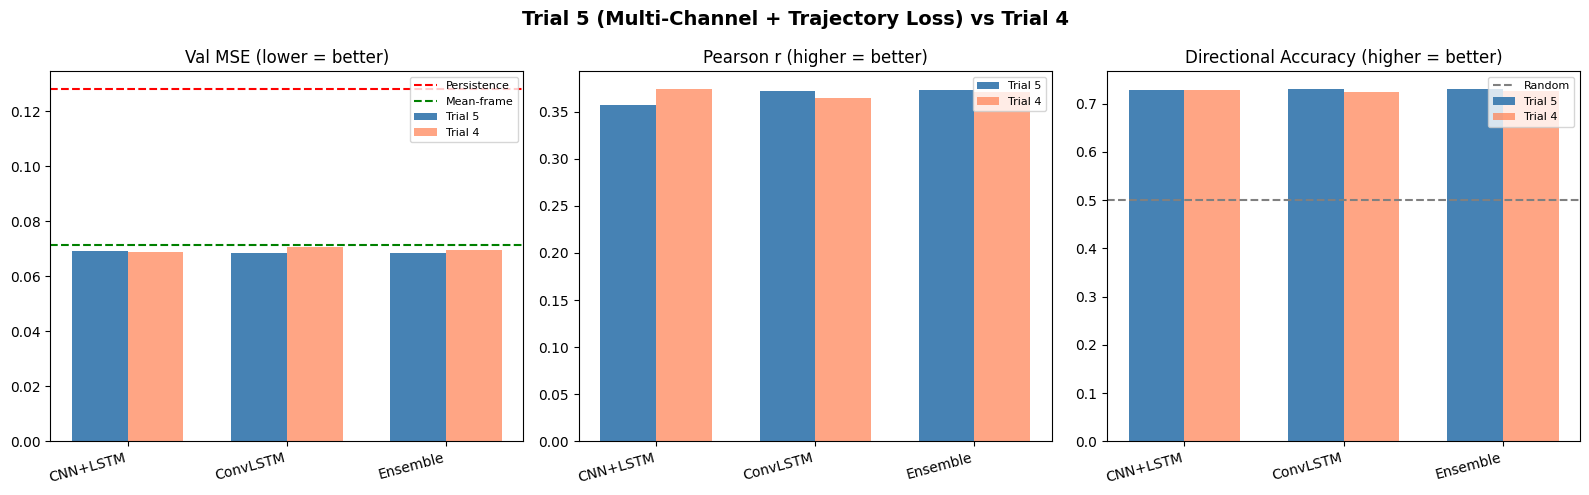

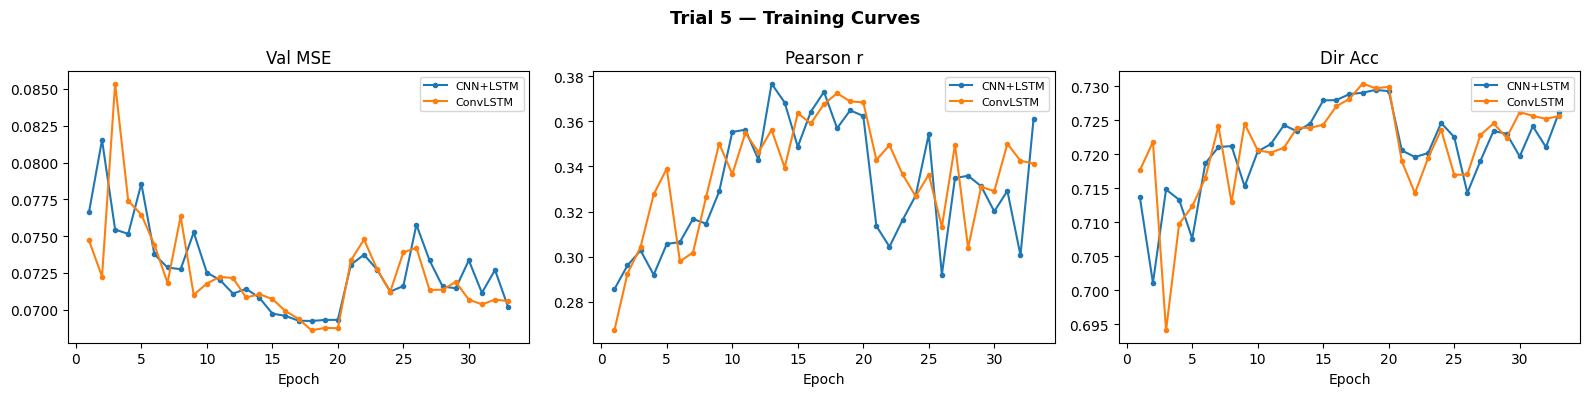


All done. Outputs saved to outputs/plots/ and outputs/predictions/


In [11]:
# Cell 11 – Full Evaluation & Comparison

val_futures = corr_video[val_snaps + HORIZON].astype(np.float32)

preds_dict = {
    'CNN+LSTM' : np.load(os.path.join(PREDS_DIR, 'trial5_cnn_lstm_val_preds.npy')),
    'ConvLSTM' : np.load(os.path.join(PREDS_DIR, 'trial5_convlstm_val_preds.npy')),
    'Ensemble' : np.load(os.path.join(PREDS_DIR, 'trial5_ensemble_val_preds.npy')),
}

results = {name: compute_metrics(p, val_futures, val_currents)
           for name, p in preds_dict.items()}

results['Persistence'] = dict(mse=persistence_mse, pearson_r=float('nan'),
                               dir_acc=0.5, vs_persist=0.0,
                               vs_mean=(mean_frame_mse - persistence_mse) / mean_frame_mse * 100)
results['Mean-frame']  = dict(mse=mean_frame_mse, pearson_r=float('nan'),
                               dir_acc=float('nan'),
                               vs_persist=(persistence_mse - mean_frame_mse) / persistence_mse * 100,
                               vs_mean=0.0)

prior_ref = {
    'T3 CNN+LSTM'  : dict(mse=0.068051, pearson_r=0.3868, dir_acc=0.732),
    'T3 ConvLSTM'  : dict(mse=0.071597, pearson_r=0.3158, dir_acc=0.724),
    'T3 Ensemble'  : dict(mse=0.068160, pearson_r=0.3798, dir_acc=0.732),
    'T4 CNN+LSTM'  : dict(mse=0.068999, pearson_r=0.3742, dir_acc=0.729),
    'T4 ConvLSTM'  : dict(mse=0.070756, pearson_r=0.3643, dir_acc=0.725),
    'T4 Ensemble'  : dict(mse=0.069592, pearson_r=0.3712, dir_acc=0.727),
}

print(f'{"Model":<18} {"Val MSE":>10} {"Pearson r":>10} {"Dir Acc":>9} {"vs Pers":>9} {"vs Mean":>9}')
print('-' * 67)
for name, m in results.items():
    r  = f"{m['pearson_r']:.4f}" if not np.isnan(m['pearson_r']) else '   n/a'
    da = f"{m['dir_acc']:.3f}"   if m['dir_acc'] is not None and not np.isnan(m['dir_acc']) else '   n/a'
    print(f"{name:<18} {m['mse']:>10.6f} {r:>10} {da:>9} "
          f"{m['vs_persist']:>+8.1f}% {m['vs_mean']:>+8.1f}%")

print('\n--- Prior Trials Reference ---')
print(f'{"Model":<18} {"Val MSE":>10} {"Pearson r":>10} {"Dir Acc":>9}')
print('-' * 47)
for name, m in prior_ref.items():
    print(f"{name:<18} {m['mse']:>10.6f} {m['pearson_r']:>10.4f} {m['dir_acc']:>9.3f}")

# ── Plots ──────────────────────────────────────────────────────────────────────
t5_names   = list(preds_dict.keys())
t5_mse     = [results[n]['mse']       for n in t5_names]
t5_pearson = [results[n]['pearson_r'] for n in t5_names]
t5_dir     = [results[n]['dir_acc']   for n in t5_names]

t4_names   = ['T4 CNN+LSTM', 'T4 ConvLSTM', 'T4 Ensemble']
t4_mse     = [prior_ref[n]['mse']       for n in t4_names]
t4_pearson = [prior_ref[n]['pearson_r'] for n in t4_names]
t4_dir     = [prior_ref[n]['dir_acc']   for n in t4_names]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Trial 5 (Multi-Channel + Trajectory Loss) vs Trial 4', fontsize=14, fontweight='bold')
x5 = np.arange(len(t5_names)); x4 = np.arange(len(t4_names)); w = 0.35

axes[0].bar(x5 - w/2, t5_mse, w, label='Trial 5', color='steelblue')
axes[0].bar(x4 + w/2, t4_mse, w, label='Trial 4', color='coral', alpha=0.7)
axes[0].axhline(persistence_mse, color='red',   linestyle='--', label='Persistence')
axes[0].axhline(mean_frame_mse,  color='green', linestyle='--', label='Mean-frame')
axes[0].set_xticks(x5); axes[0].set_xticklabels(t5_names, rotation=15, ha='right')
axes[0].set_title('Val MSE (lower = better)'); axes[0].legend(fontsize=8)

axes[1].bar(x5 - w/2, t5_pearson, w, label='Trial 5', color='steelblue')
axes[1].bar(x4 + w/2, t4_pearson, w, label='Trial 4', color='coral', alpha=0.7)
axes[1].set_xticks(x5); axes[1].set_xticklabels(t5_names, rotation=15, ha='right')
axes[1].set_title('Pearson r (higher = better)'); axes[1].legend(fontsize=8)

axes[2].bar(x5 - w/2, t5_dir, w, label='Trial 5', color='steelblue')
axes[2].bar(x4 + w/2, t4_dir, w, label='Trial 4', color='coral', alpha=0.7)
axes[2].axhline(0.5, color='grey', linestyle='--', label='Random')
axes[2].set_xticks(x5); axes[2].set_xticklabels(t5_names, rotation=15, ha='right')
axes[2].set_title('Directional Accuracy (higher = better)'); axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'trial5_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

# Training curves
hist_dict = {'CNN+LSTM': hist_cnn_lstm, 'ConvLSTM': hist_convlstm}
fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4))
fig2.suptitle('Trial 5 — Training Curves', fontsize=13, fontweight='bold')
for ax, (key, label) in zip(axes2, [('va_mse','Val MSE'),('pearson_r','Pearson r'),('dir_acc','Dir Acc')]):
    for name, hist in hist_dict.items():
        vals = [h[key] for h in hist if h[key] is not None]
        ax.plot(range(1, len(vals)+1), vals, label=name, marker='o', markersize=3)
    ax.set_xlabel('Epoch'); ax.set_title(label); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'trial5_training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

print('\nAll done. Outputs saved to outputs/plots/ and outputs/predictions/')
